# HW2 Part 2 — Single-Stock Risk Report

A parameterized risk report for one ticker over one date range, built from the cleaned table `ohlc_hw_cleaned` that `01_data_cleaning.ipynb` writes to the local database.

**Run it** from the `Ananya_Das/` folder (so `db_path` and the helper module resolve):

```bash
papermill 02_stock_report_template.ipynb reports/example.ipynb \
    -p ticker MSFT -p start_date 2024-06-01 -p end_date 2024-11-30
```

**Conventions** (from the assignment): report returns, volatility, Sharpe and the daily statistics use daily **log returns of adjusted close**; drawdown is measured on adjusted close; metrics stay as fractions and are formatted as percentages only for display; an undefined metric is `NaN` and shown as `N/A`. The calculation functions live in `hw2_report.py`, each with a docstring, and are unit-tested in `tests/test_hw2_report.py`.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scrapbook as sb
from IPython.display import display

import hw2_report as hr
from hw2_report import (calculate_max_drawdown, calculate_returns, calculate_sharpe_ratio,
                        calculate_volatility)

pd.set_option("display.width", 160)

## 2.1 Parameters

The next cell carries the Jupyter cell tag **`parameters`** (JupyterLab: Property Inspector → Cell Tags), so Papermill inserts an `injected-parameters` cell after it that overrides these defaults. `db_path` is relative to the homework folder, which keeps the notebook portable to any checkout with a local copy of the database.

In [2]:
# Parameters
ticker = "AAPL"  # Stock ticker to analyze
start_date = "2024-01-01"  # Analysis start date
end_date = "2024-12-31"  # Analysis end date
db_path = "data/data.db"  # local database with ohlc_hw_cleaned (relative to this folder)
volatility_window = 20  # trading days in the rolling volatility window

In [3]:
# Parameters
ticker = "MRK"
start_date = "2024-06-01"
end_date = "2024-11-30"
db_path = "/Users/ananya/Documents/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW2/Ananya_Das/data/data.db"


## 2.2 Data loading

The parameters are validated first (non-empty ticker, real dates in order, window ≥ 2). The query is read-only and inclusive at both ends (`start_date <= ts <= end_date`). A report needs at least `volatility_window + 1` prices — 20 returns require 21 prices — otherwise it stops with an error that states the ticker's available history.

In [4]:
ticker, start_date, end_date = hr.validate_parameters(ticker, start_date, end_date, volatility_window)
prices_df = hr.load_report_data(db_path, ticker, start_date, end_date, min_prices=volatility_window + 1)

trading_days = len(prices_df)
first_date = prices_df.index.min().strftime("%Y-%m-%d")
last_date = prices_df.index.max().strftime("%Y-%m-%d")
print(f"{ticker} from {start_date} to {end_date}: {trading_days} trading days")
print(f"Actual first observation: {first_date} | actual last observation: {last_date}")

late_start = len(pd.bdate_range(start_date, first_date)) - 1
early_end = len(pd.bdate_range(last_date, end_date)) - 1
if late_start > 3:
    print(f"Note: data starts {late_start} business days after the requested start date.")
if early_end > 3:
    print(f"Note: the delivered history ends {early_end} business days before the requested end date; "
          "the report covers only the observed period and nothing is extrapolated.")
display(prices_df.head())
display(prices_df.tail())

MRK from 2024-06-01 to 2024-11-30: 126 trading days
Actual first observation: 2024-06-03 | actual last observation: 2024-11-29


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-06-03,125.77,128.95,125.77,128.42,126.81,7702676
2024-06-04,127.15,129.36,126.88,128.71,127.09,6440167
2024-06-05,128.48,129.94,128.07,129.45,127.82,5009502
2024-06-06,129.16,130.93,128.90,130.52,128.88,8088641
2024-06-07,130.35,131.37,130.21,130.67,129.03,4945600


,open,high,low,close,adj_close,volume
ts,,,,,,
2024-11-22,100.33,101.79,98.93,99.18,99.18,14031200
2024-11-25,100.09,101.74,99.51,101.16,101.16,34659100
2024-11-26,101.48,101.80,99.70,101.62,101.62,9324100
2024-11-27,101.65,103.45,101.64,103.12,103.12,9802200
2024-11-29,102.88,103.04,101.53,101.64,101.64,6081200


In [5]:
input_checks = hr.check_report_data(prices_df)
display(input_checks.to_frame())
if input_checks.sum():
    raise ValueError(f"{ticker}: input data failed checks: {input_checks[input_checks > 0].to_dict()}")
print("Input checks passed: no missing or invalid values, valid OHLC bounds, unique increasing dates.")

,failing rows
missing or non-finite value,0
nonpositive price,0
OHLC bounds violated,0
negative volume,0
duplicate date,0
dates not increasing,0


Input checks passed: no missing or invalid values, valid OHLC bounds, unique increasing dates.


## 2.3 Risk metrics

| function | definition |
|---|---|
| `calculate_returns(prices)` | daily log return `log(p_t / p_{t-1})` |
| `calculate_volatility(returns, window=20)` | `returns.rolling(window).std() * sqrt(252)` — annualized, sample std; the first `window` dates have no estimate |
| `calculate_max_drawdown(prices)` | per-date drawdown `(price - running_max) / running_max`; it can recover. Maximum drawdown is its minimum |
| `calculate_sharpe_ratio(returns, risk_free_rate=0.02)` | `(mean * 252 - rf) / (std * sqrt(252))`; `NaN` with < 2 returns or zero volatility |

The name `calculate_max_drawdown` is kept from the assignment, but it returns the drawdown **series**, as the instructions specify.

The four functions are defined once in `hw2_report.py` (so the unit tests and every Papermill run use the same code) and imported by name in the first cell. The next cell prints each function's full docstring from the running kernel and then applies them to this report's prices.

In [6]:
import inspect

for function in [calculate_returns, calculate_volatility, calculate_max_drawdown, calculate_sharpe_ratio]:
    print(f"{function.__name__}{inspect.signature(function)}\n    "
          + inspect.getdoc(function).replace("\n", "\n    ") + "\n")

prices = prices_df["adj_close"]
log_returns = calculate_returns(prices)
rolling_volatility = calculate_volatility(log_returns, volatility_window)
drawdown = calculate_max_drawdown(prices)
moving_average_50 = prices.rolling(hr.MA_WINDOW).mean()
sharpe_ratio = calculate_sharpe_ratio(log_returns)

analysis = pd.DataFrame({"adj_close": prices, "log_return": log_returns, "rolling_volatility": rolling_volatility,
                         "drawdown": drawdown, "ma_50": moving_average_50})
display(analysis.iloc[volatility_window - 2:volatility_window + 3])

calculate_returns(prices: 'pd.Series') -> 'pd.Series'
    Calculate daily log returns ``log(p_t / p_{t-1})``.
    
    The first value is ``NaN``; a missing price makes the returns on both
    sides of it ``NaN`` (nothing is filled).

calculate_volatility(returns: 'pd.Series', window: 'int' = 20) -> 'pd.Series'
    Calculate annualized rolling volatility.
    
    Sample standard deviation (``ddof=1``) of the last ``window`` daily log
    returns times ``sqrt(252)``. A value exists only once a full window of
    returns is available, so the first ``window`` prices have no estimate
    (the warm-up is left as ``NaN``, never filled with zero).

calculate_max_drawdown(prices: 'pd.Series') -> 'pd.Series'
    Return per-date drawdown from the running price peak.
    
    ``(price - running_max) / running_max``: zero at a new high, negative
    below it, and it can recover. The maximum drawdown for the summary is
    ``drawdown.min()``; the running worst drawdown would be ``cummin()``.

calc

,adj_close,log_return,rolling_volatility,drawdown,ma_50
ts,,,,,
2024-06-28,122.98,-0.047481,NaN,-0.068898,NaN
2024-07-01,127.05,0.032559,NaN,-0.038083,NaN
2024-07-02,126.87,-0.001418,0.246352,-0.039446,NaN
2024-07-03,125.01,-0.014769,0.251669,-0.053528,NaN
2024-07-05,125.61,0.004788,0.251367,-0.048985,NaN


In [7]:
# consistency checks on the calculations
assert pd.isna(analysis["log_return"].iloc[0])                                   # first return undefined
assert analysis["rolling_volatility"].iloc[:volatility_window].isna().all()       # warm-up is NaN, not zero
assert analysis["rolling_volatility"].iloc[volatility_window:].notna().all()
assert np.isclose(np.expm1(log_returns.sum()), prices.iloc[-1] / prices.iloc[0] - 1)
assert (drawdown <= 0).all() and drawdown.iloc[0] == 0

print(f"First rolling-volatility estimate: {rolling_volatility.first_valid_index():%Y-%m-%d} "
      f"(after {volatility_window} returns); mean rolling volatility {rolling_volatility.mean():.2%}")
if moving_average_50.notna().any():
    print(f"50-day moving average available from {moving_average_50.first_valid_index():%Y-%m-%d}")
else:
    print(f"50-day moving average unavailable: the report has only {trading_days} prices (50 needed). "
          "The price chart shows the available data without it.")
print(f"Sharpe ratio: {hr.format_value(sharpe_ratio, '{:.2f}')} | "
      f"maximum drawdown: {drawdown.min():.2%} on {drawdown.idxmin():%Y-%m-%d}")

First rolling-volatility estimate: 2024-07-02 (after 20 returns); mean rolling volatility 23.27%
50-day moving average available from 2024-08-13
Sharpe ratio: -1.93 | maximum drawdown: -27.08% on 2024-11-15


## 2.4 Visualization

* **Price and 50-day MA** — each price segment takes the colour of its ending date's rolling volatility: red above the report's mean rolling volatility, green at or below it, gray during the warm-up before an estimate exists. The threshold uses the whole report period, so the colouring is retrospective.
* **Daily Returns** — daily log returns (%), green for gains, red for losses (gray for an unchanged close), with a zero line.
* **Rolling Volatility** — the 20-day estimate with its mean; shaded red above the mean and green at or below it. The warm-up gap is left empty.
* **Maximum Drawdown** — drawdown from the running peak as layered transparent red fills that darken toward the trough; the maximum drawdown is marked.

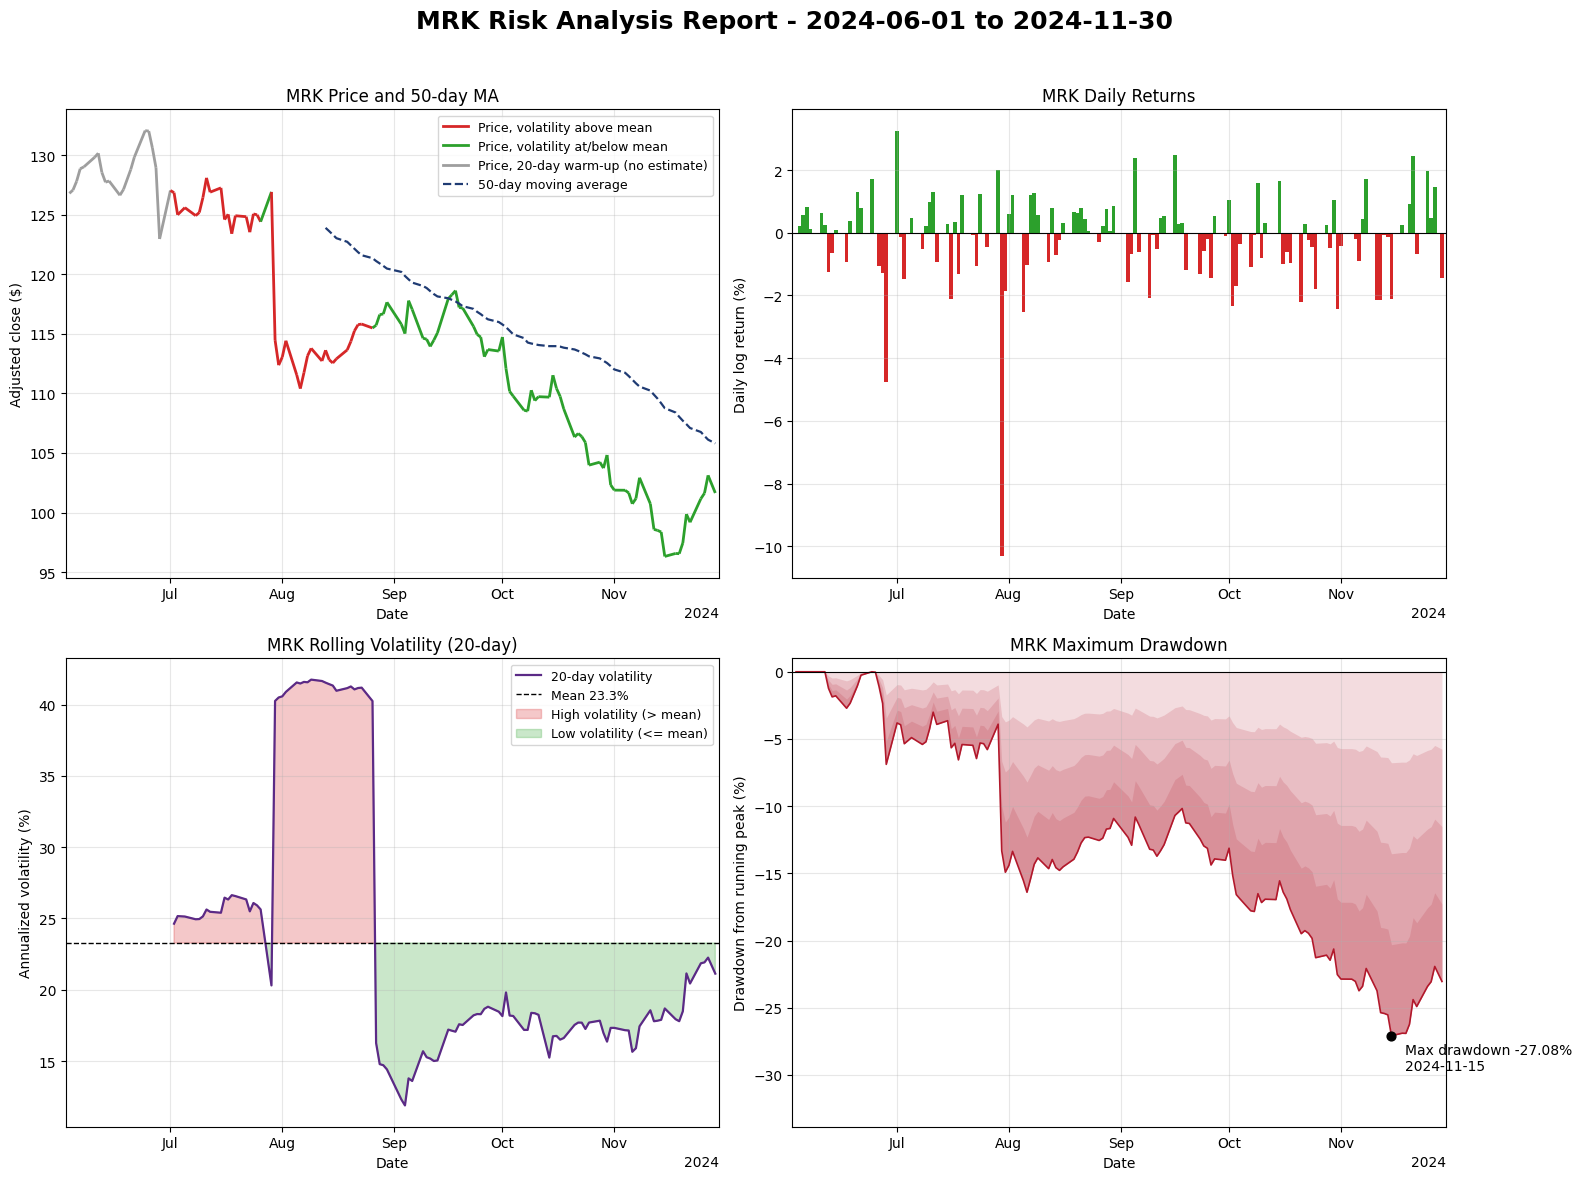

In [8]:
fig = hr.plot_risk_report(prices_df, ticker, start_date, end_date, volatility_window)
assert tuple(fig.get_size_inches()) == (16, 12)
plt.show()

## 2.5 Summary statistics

Total return is `last_adj_close / first_adj_close - 1`. With `n` non-missing log returns, annualized return is `exp(sum(log_returns) * 252 / n) - 1` and annualized volatility is `std(log_returns) * sqrt(252)` over the whole period (not the mean rolling volatility used in Part 3). Best/worst day and the up/down averages use log returns; positive days are divided by **all** non-missing returns, zero days included.

In [9]:
stats = hr.summary_statistics(prices, volatility_window)
assert np.isclose(stats["max_drawdown"], drawdown.min())
assert stats["sharpe_ratio"] == sharpe_ratio or (np.isnan(stats["sharpe_ratio"]) and np.isnan(sharpe_ratio))

summary_table = hr.format_summary_table(stats)
print(f"{ticker} | {first_date} to {last_date} | {stats['n_prices']} prices, {stats['n_returns']} daily log returns\n")
print(f"{'Metric':<24}  {'Value':>8}\n{'-' * 24}  {'-' * 8}")
for metric, value in summary_table.itertuples(index=False):
    print(f"{metric:<24}  {value:>8}")

MRK | 2024-06-03 to 2024-11-29 | 126 prices, 125 daily log returns

Metric                       Value
------------------------  --------
Total Return               -19.85%
Annualized Return          -35.98%
Annualized Volatility       24.09%
Sharpe Ratio                 -1.93
Maximum Drawdown           -27.08%
Best Day                    +3.26%
Worst Day                  -10.32%
Positive Days                47.2%
Average Up Day              +0.87%
Average Down Day            -1.11%


### Saving results for the batch run

`sb.glue` stores named results inside the executed notebook so the Part 3 script can collect them from **successful** reports without recomputing. The identity of the report (ticker, requested and actual dates, number of trading days) is stored as individual scraps; the metrics are stored together in one `report_metrics` dictionary as fractions, where an undefined value (for example Sharpe with zero volatility) is `None` — Scrapbook cannot store a bare `None`, and `NaN` would make the notebook file invalid JSON. `report_complete` is written last, so its presence means every earlier cell succeeded.

In [10]:
identity = {"ticker": ticker, "start_date": start_date, "end_date": end_date,
            "first_date": first_date, "last_date": last_date, "trading_days": trading_days}
metric_names = ["avg_daily_return", "avg_volatility", "max_drawdown", "sharpe_ratio", "total_return",
                "annualized_return", "annualized_volatility", "best_day", "worst_day", "positive_days",
                "avg_up_day", "avg_down_day", "n_returns"]
report_metrics = {name: hr.to_glue_value(stats[name]) for name in metric_names}
for name, value in identity.items():
    sb.glue(name, value)
sb.glue("report_metrics", report_metrics)
sb.glue("report_complete", True)
undefined = [name for name, value in report_metrics.items() if value is None]
print(f"Saved {len(identity)} identity scraps and report_metrics with {len(report_metrics)} values"
      + (f"; undefined: {', '.join(undefined)}" if undefined else ""))

Saved 6 identity scraps and report_metrics with 13 values
